# Proyecto final: Airbnb Bogotá
## Pregunta 1: ¿cuánto se debería cobrar por noche según las características de la propiedad?

**Datos:** Inside Airbnb, Bogotá, septiembre 2026.
**Variable a predecir (y):** `price` (precio por noche en COP).
**Tipo de problema:** regresión, porque el precio es un número continuo.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor

DATOS = Path("../datos")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

print("Datos encontrados:", sorted(p.name for p in DATOS.glob("*.csv.gz")))

# las figuras se muestran dentro del cuaderno
%matplotlib inline

TINTA, ACENTO, MORADO, GRIS = "#1B1A2F", "#E8963C", "#4C3F91", "#8A879E"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": "#E6E4EC",
                     "grid.linewidth": 0.7, "legend.frameon": False})


## Paso 1: ¿Necesitamos ML?
Primero se carga la tabla `listings`, que tiene una fila por alojamiento publicado en Airbnb Bogotá, y se revisa qué trae.

In [ ]:
listings = pd.read_csv(
    DATOS / "listings.csv.gz",
    dtype={"price": str},
    low_memory=False,
)

print("Filas y columnas:", listings.shape)

### Regla a mano (punto de partida)
Si no se usara ML, un dueño podría mirar el precio típico (la mediana) de su barrio y cobrar eso. Se calcula qué tan lejos queda esa regla del precio real. Si el modelo no la supera, no vale la pena usar ML.

In [ ]:
def a_numero(serie):
    sin_signo = serie.str.replace("$", "", regex=False)
    sin_coma = sin_signo.str.replace(",", "", regex=False)
    return sin_coma.astype(float)

listings["price_num"] = a_numero(listings["price"])
datos = listings.dropna(subset=["price_num"]).copy()
print("Alojamientos con precio:", datos.shape[0])

In [ ]:
train, test = train_test_split(
    datos,
    test_size=0.2,
    random_state=42,
)
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])

In [ ]:
#La mediana por la aasimetría extrema de los datos
mediana_barrio = train.groupby("neighbourhood_cleansed")["price_num"].median()
mediana_global = train["price_num"].median()
pred_regla = test["neighbourhood_cleansed"].map(mediana_barrio).fillna(mediana_global)

mae_regla = mean_absolute_error(test["price_num"], pred_regla)
rmse_regla = np.sqrt(mean_squared_error(test["price_num"], pred_regla))
r2_regla = r2_score(test["price_num"], pred_regla)

print(f"MAE:  ${mae_regla:,.0f}")
print(f"RMSE: ${rmse_regla:,.0f}")
print(f"R²:   {r2_regla:.3f}")

### Conclusión: ¿necesitamos ML?
La regla de la mediana por barrio se equivoca en promedio **\$118.248** por noche (MAE), y su R² es casi 0 (-0,009), o sea que casi no explica el precio. Además, el RMSE (**\$462.097**) es mucho mayor que el MAE, lo que indica que hay precios extremos que distorsionan el error. Queda claro que el barrio solo no basta: el precio también depende del tamaño y del tipo de alojamiento, así que vale la pena probar modelos de ML que combinen varias variables. Este MAE de **\$118.248** es el número a superar (más adelante, después de limpiar los precios extremos, el punto de comparación pasa a ser **\$92.943**).

## Paso 2: Datos

**De dónde salen:** Inside Airbnb, https://insideairbnb.com/get-the-data/ (sección "Bogotá, Distrito Capital, Colombia", compilado el 14 de septiembre de 2026).

**Recolección** Salen de métodos de scraping de la página de Airbnb.

**Cómo se descargan:** Datos abiertos de uso libre, son 3 archivos tipo `.csv.gz`.

| Tabla | Qué es una fila |
|---|---|
| `listings` | un alojamiento publicado |
| `reviews` | un comentario que dejó un huésped |
| `calendar` | un alojamiento en un día futuro (si está disponible o no) |



In [ ]:
calendar_cols = pd.read_csv(DATOS / "calendar.csv.gz", nrows=0).columns
reviews_cols = pd.read_csv(DATOS / "reviews.csv.gz", nrows=0).columns
print("calendar:", list(calendar_cols))
print("reviews:", list(reviews_cols))

In [ ]:
calendar = pd.read_csv(
    DATOS / "calendar.csv.gz",
    usecols=["listing_id", "date", "available"],
)
reviews = pd.read_csv(
    DATOS / "reviews.csv.gz",
    usecols=["listing_id", "date"],
)

print(f"listings: {listings.shape[0]:,} filas x {listings.shape[1]} columnas")
print(f"calendar: {len(calendar):,} filas x {len(calendar_cols)} columnas (en el archivo)")
print(f"reviews:  {len(reviews):,} filas x {len(reviews_cols)} columnas (en el archivo)")

### Manejo especial de calendar y reviews [Las 2 bases adicionales como complemento]
Listings tiene una fila por alojamiento, pero calendar tiene una fila por alojamiento y por día, y reviews una por comentario. Para unirlas hay que resumirlas:
- `pct_ocupado_90d`: de los próximos 90 días del calendario, qué proporción está no disponible (ocupado o bloqueado).
- `reviews_ult_12m`: cuántos comentarios recibió el alojamiento en el último año.

Todo se cuenta desde una **fecha de corte**, que es el "hoy" de los datos. Estas dos variables quedan como candidatas; más adelante se explica por qué finalmente no entran al modelo.

**Se hizo un análisis de sensibilidad de los comentarios, pero esa variable no resultaba relevante enn el modelo y no le sirve a un nuevo usuario que nunca ha operado**

**La variable ocupación futura, que sale de calendario tiene una distribusión muy rica en el corto plazo, pero a largo plazo es totalmente incierto, su aporte a la variabiilidad explicada de los datos es baja en el modelo final**


In [ ]:
calendar["date"] = pd.to_datetime(calendar["date"])
reviews["date"] = pd.to_datetime(reviews["date"])
fecha_corte = calendar["date"].min() - pd.Timedelta(days=1)

print("Fecha de corte:", fecha_corte.date())
print("Calendar va de", calendar["date"].min().date(), "a", calendar["date"].max().date())
print("Reviews van de", reviews["date"].min().date(), "a", reviews["date"].max().date())

In [ ]:
primeros_90 = calendar[calendar["date"] <= fecha_corte + pd.Timedelta(days=90)]
esta_ocupado = primeros_90["available"] == "f"
pct_ocupado_90d = esta_ocupado.groupby(primeros_90["listing_id"]).mean()
pct_ocupado_90d.name = "pct_ocupado_90d"

en_ultimo_anio = (reviews["date"] > fecha_corte - pd.Timedelta(days=365)) & (reviews["date"] <= fecha_corte)
reviews_ult_12m = reviews[en_ultimo_anio].groupby("listing_id").size()
reviews_ult_12m.name = "reviews_ult_12m"

print("Alojamientos con calendario:", len(pct_ocupado_90d))
print("Alojamientos con comentarios en el último año:", len(reviews_ult_12m))
print(pct_ocupado_90d.describe())
print(reviews_ult_12m.describe())

### Tabla principal (una fila por alojamiento)
Se unen a `listings` las dos variables resumidas de calendar y reviews, usando el `id` del alojamiento. Los que no tuvieron comentarios en el último año quedan con 0. También se crea `dias_desde_ultimo_review`: cuántos días pasaron entre el último comentario y la fecha de corte. Como cambió la tabla, se repite la división entrenamiento/prueba con la misma semilla y se comprueba que la regla a mano da lo mismo que antes.

In [ ]:
datos = listings.merge(pct_ocupado_90d, left_on="id", right_index=True, how="left")
datos = datos.merge(reviews_ult_12m, left_on="id", right_index=True, how="left")
datos["reviews_ult_12m"] = datos["reviews_ult_12m"].fillna(0)
datos["dias_desde_ultimo_review"] = (fecha_corte - pd.to_datetime(datos["last_review"])).dt.days
datos["dias_desde_ultimo_review"] = datos["dias_desde_ultimo_review"].clip(lower=0)
datos = datos.dropna(subset=["price_num"]).copy()

print("Filas y columnas:", datos.shape)
print("¿Cada alojamiento aparece una sola vez?", datos["id"].is_unique)
datos[["id", "neighbourhood_cleansed", "price_num", "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review"]].head()

In [ ]:
# Donde estan los alojamientos y a que precio
con_precio = datos[datos["price_num"].notna()].copy()
cortes = con_precio["price_num"].quantile([1/3, 2/3]).tolist()
con_precio["banda"] = pd.cut(con_precio["price_num"],
                             [0] + cortes + [con_precio["price_num"].max()],
                             labels=["tercio económico", "tercio medio", "tercio alto"])

fig, ax = plt.subplots(figsize=(6.8, 6.8))
for etiqueta, color in [("tercio económico", GRIS),
                        ("tercio medio", MORADO),
                        ("tercio alto", ACENTO)]:
    grupo = con_precio[con_precio["banda"] == etiqueta]
    ax.scatter(grupo["longitude"], grupo["latitude"], s=5, alpha=0.45,
               color=color, edgecolors="none", rasterized=True,
               label=f"{etiqueta} (hasta ${grupo['price_num'].max():,.0f})")
ax.set_title("Ubicación de los alojamientos y su precio")
ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax.legend(loc="upper left", fontsize=8.5, markerscale=3)
plt.show()

In [ ]:
train, test = train_test_split(datos, test_size=0.2, random_state=42)
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])

mediana_barrio = train.groupby("neighbourhood_cleansed")["price_num"].median()
mediana_global = train["price_num"].median()
pred_regla = test["neighbourhood_cleansed"].map(mediana_barrio).fillna(mediana_global)
print(f"MAE de la regla a mano: ${mean_absolute_error(test['price_num'], pred_regla):,.0f}")
print(f"R² de la regla a mano: {r2_score(test['price_num'], pred_regla):.3f}")

In [ ]:
# Dispersion del precio dentro de cada localidad, es parte de la justificación de por qué el barrio no basta
#Logarítmica porque el precio es muy asimétrico, y sin los puntos extremos
top_barrios = train["neighbourhood_cleansed"].value_counts().head(10).index
precios_barrio = [train.loc[train["neighbourhood_cleansed"] == b, "price_num"] for b in top_barrios]

fig, ax = plt.subplots(figsize=(10, 4))
caja = ax.boxplot(precios_barrio, showfliers=False, patch_artist=True, widths=0.6)
for pieza in caja["boxes"]:
    pieza.set_facecolor(ACENTO); pieza.set_alpha(0.55); pieza.set_edgecolor(TINTA)
for pieza in caja["medians"]:
    pieza.set_color(TINTA); pieza.set_linewidth(1.6)
ax.set_xticks(range(1, len(top_barrios) + 1))
ax.set_xticklabels(top_barrios, rotation=30, ha="right", fontsize=9)
ax.set_yscale("log")
ax.set_title("Precio por noche dentro de cada localidad")
ax.set_ylabel("precio por noche, escala logarítmica")
plt.tight_layout()
plt.show()

## Paso 3: Limpieza
**Se revisan cuatro cosas:**

*Duplicados

*Errores de formato y digitación

*Datos faltantes

*Fugas

Se empieza por los duplicados y por los precios extremos, porque el RMSE era mucho más grande que el MAE y eso hace sospechar que hay precios exagerados. Solo se mira el conjunto de entrenamiento, para no decidir nada con lo que debe ser la prueba final.

In [ ]:
print("Filas completamente duplicadas:", datos.duplicated().sum())
print("Ids repetidos:", datos["id"].duplicated().sum())
print()
print(train["price_num"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99, 0.999]))

In [ ]:
columnas_ver = ["price_num", "property_type", "room_type", "accommodates", "neighbourhood_cleansed"]
print("Los 10 más caros:")
display(train.nlargest(10, "price_num")[columnas_ver])
print("Los 5 más baratos:")
display(train.nsmallest(5, "price_num")[columnas_ver])

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

tope_vista = train["price_num"].quantile(0.99)
visibles = train.loc[train["price_num"] <= tope_vista, "price_num"]
fuera_de_vista = (train["price_num"] > tope_vista).sum()

ejes[0].hist(visibles, bins=50, color=ACENTO, edgecolor="white", linewidth=0.3)
ejes[0].set_title("Precio por noche (pesos)")
ejes[0].set_xlabel(f"pesos por noche, hasta ${tope_vista:,.0f}")
ejes[0].set_ylabel("alojamientos")
ejes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v:,.0f}"))
ejes[0].text(0.97, 0.93, f"{fuera_de_vista} alojamientos quedan por encima del recorte, "
             f"hasta ${train['price_num'].max():,.0f}",
             transform=ejes[0].transAxes, ha="right", va="top", fontsize=8, color=TINTA)

ejes[1].hist(np.log1p(train["price_num"]), bins=50, color=MORADO, edgecolor="white", linewidth=0.3)
ejes[1].set_title("Logaritmo del precio")
ejes[1].set_xlabel("log(1 + precio por noche)")
ejes[1].set_ylabel("alojamientos")

plt.tight_layout()
plt.show()


### Atípicos
**Mejor criterio para recortar atípicos es el precio por huésped, recortar con solo precio quita residencias grandes reales**


**(usamos Q3+3*IQR)** 

Un corte de Tukey sobre el precio total se llevaría casas que son caras por tamaño y no por error. Un precio total alto no es necesariamente un error sino que depende del tamaño. 

Por eso se aplica la misma regla de Tukey, pero sobre el **precio por huésped** (precio dividido entre `accommodates`), que sí compara alojamientos de tamaños distintos. El tope se calcula solo con entrenamiento y se aplica igual a entrenamiento y prueba, porque es una regla fija sobre errores de digitación en la etiqueta. El precio por huésped solo sirve para detectar los extremos: lo que el modelo predice sigue siendo el precio por noche.

In [ ]:
def por_huesped(df):
    return df["price_num"] / df["accommodates"].clip(lower=1)

columnas_ver = ["price_num", "property_type", "room_type", "accommodates", "neighbourhood_cleansed"]

log_pp = np.log1p(por_huesped(train))
q1, q3 = log_pp.quantile([0.25, 0.75])
iqr = q3 - q1
tope_pp = np.expm1(q3 + 3 * iqr)
print(f"Tope de Tukey por huésped: ${tope_pp:,.0f}")

extremo_train = por_huesped(train) > tope_pp
extremo_test = por_huesped(test) > tope_pp
print("Extremos en entrenamiento:", extremo_train.sum(), "| en prueba:", extremo_test.sum())

display(train[extremo_train].assign(por_huesped=por_huesped(train[extremo_train]))
        .sort_values("por_huesped")[columnas_ver + ["por_huesped"]].head(15))


In [ ]:
# El corte por huesped, visto sobre el precio y la capacidad
fig, ax = plt.subplots(figsize=(8.5, 4.2))
dentro = train[~extremo_train]
fuera = train[extremo_train]
ax.scatter(dentro["accommodates"], dentro["price_num"], s=6, alpha=0.18,
           color=MORADO, edgecolors="none", label="dentro del tope")
ax.scatter(fuera["accommodates"], fuera["price_num"], s=34, color=ACENTO,
           edgecolors=TINTA, linewidth=0.5, label="por encima del tope")
capacidad = np.arange(1, int(train["accommodates"].max()) + 1)
ax.plot(capacidad, tope_pp * capacidad, color=TINTA, linewidth=1.3,
        linestyle="--", label="tope de Tukey por huésped")
ax.set_yscale("log")
ax.set_title("El criterio por huésped descarta errores y conserva viviendas grandes")
ax.set_xlabel("huéspedes que admite"); ax.set_ylabel("precio por noche, escala logarítmica")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

### Aplicar el corte
Se quitan los alojamientos con precio por huésped mayor a **\$665.251** (el tope de Tukey). Son 71 de entrenamiento y 23 de prueba, cerca del 0,5 %, y se sacan de los dos grupos porque son errores en la etiqueta y no tiene sentido medir al modelo contra precios imposibles. Después se recalcula la regla a mano para comparar antes y después.

In [ ]:
def regla_a_mano(entreno, prueba):
    mediana_barrio = entreno.groupby("neighbourhood_cleansed")["price_num"].median()
    mediana_global = entreno["price_num"].median()
    return prueba["neighbourhood_cleansed"].map(mediana_barrio).fillna(mediana_global)

def metricas(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred),
        "RMSLE": np.sqrt(mean_squared_error(np.log1p(y_real), np.log1p(y_pred))),
    }

antes = metricas(test["price_num"], regla_a_mano(train, test))

train = train[por_huesped(train) <= tope_pp].copy()
test = test[por_huesped(test) <= tope_pp].copy()
print("Entrenamiento:", train.shape[0], "| Prueba:", test.shape[0])

despues = metricas(test["price_num"], regla_a_mano(train, test))
tabla = pd.DataFrame({"Antes de limpiar": antes, "Después de limpiar": despues})

In [ ]:
display(tabla.map(lambda x: f"{x:,.3f}"))

### Conclusión: precios extremos
Se quitaron 71 alojamientos de entrenamiento y 23 de prueba (cerca del 0,5 %) cuyo precio por huésped pasaba de **\$665.251**, el tope de Tukey. Un corte sobre el precio total se habría llevado casas reales de 16 huéspedes, y el corte por huésped no. Después de limpiar, la regla a mano mejoró: el MAE bajó de **\$118.248** a **\$92.943**, el RMSE de **\$462.097** a **\$202.499** y el RMSLE de 0,663 a 0,621. El R² sigue casi en cero (0,005), o sea que el barrio solo no explica el precio. Desde ahora, la regla a mano con MAE **\$92.943** es el número a superar.

### Faltantes
Se revisa cuáles de las columnas candidatas tienen datos vacíos y cuántos. Para cada una con faltantes se compara el error de varias formas de rellenarlos, como hizo el profesor con la edad en Titanic, en lugar de escoger la media sin justificar.

In [ ]:
columnas_candidatas = [
    "property_type", "room_type", "neighbourhood_cleansed",
    "latitude", "longitude",
    "accommodates", "bedrooms", "beds", "bathrooms", "bathrooms_text",
    "amenities", "minimum_nights", "host_listings_count", "host_is_superhost",
    "review_scores_rating", "availability_90",
    "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review",
]

presentes = [c for c in columnas_candidatas if c in train.columns]
ausentes = [c for c in columnas_candidatas if c not in train.columns]
print("No existen en la tabla:", ausentes)

resumen = pd.DataFrame({
    "tipo": train[presentes].dtypes.astype(str),
    "faltantes": train[presentes].isna().sum(),
    "porcentaje": (train[presentes].isna().mean() * 100).round(1),
}).sort_values("faltantes", ascending=False)
display(resumen)

### Imputación o "Rellenar los faltantes"
Para no escoger la media sin justificar, se comparan cuatro formas de rellenar: la media, la mediana global, la mediana por grupo y una regresión (bosque aleatorio). Se toman los valores que sí se conocen, se esconde el 20 %, se adivinan con cada método y se mide el error (MAE). Gana el de menor error. Se hace en `beds`, `bedrooms` y `review_scores_rating`. Las otras (`minimum_nights`, con 6 faltantes) son tan pocas que se usa la mediana.

In [ ]:
def comparar_imputacion(columna, grupo):
    conocidos = train[train[columna].notna()].copy()
    X = pd.concat([
        conocidos[["accommodates", "latitude", "longitude"]],
        pd.get_dummies(conocidos["room_type"]).astype(float),
    ], axis=1)
    y = conocidos[columna]
    X_fit, X_ev, y_fit, y_ev = train_test_split(X, y, test_size=0.2, random_state=42)

    err_media = mean_absolute_error(y_ev, np.full(len(y_ev), y_fit.mean()))
    err_mediana = mean_absolute_error(y_ev, np.full(len(y_ev), y_fit.median()))
    med_grupo = y_fit.groupby(conocidos.loc[y_fit.index, grupo]).median()
    pred_grupo = conocidos.loc[y_ev.index, grupo].map(med_grupo).fillna(y_fit.median())
    err_grupo = mean_absolute_error(y_ev, pred_grupo)
    bosque = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    bosque.fit(X_fit, y_fit)
    err_reg = mean_absolute_error(y_ev, bosque.predict(X_ev))

    return {
        "Media": err_media, "Mediana global": err_mediana,
        "Mediana por grupo": err_grupo, "Regresión (bosque)": err_reg,
    }

resultados = pd.DataFrame({
    "beds (grupo: accommodates)": comparar_imputacion("beds", "accommodates"),
    "bedrooms (grupo: accommodates)": comparar_imputacion("bedrooms", "accommodates"),
    "review_scores_rating (grupo: room_type)": comparar_imputacion("review_scores_rating", "room_type"),
}).T
display(resultados.map(lambda x: f"{x:,.3f}"))

In [ ]:
# Error de cada forma de rellenar los faltantes
fig, ax = plt.subplots(figsize=(9.5, 4))
posicion = np.arange(len(resultados))
ancho = 0.2
paleta = [GRIS, MORADO, ACENTO, TINTA]
for i, metodo in enumerate(resultados.columns):
    ax.bar(posicion + (i - 1.5) * ancho, resultados[metodo], width=ancho,
           label=metodo, color=paleta[i % len(paleta)])
ax.set_xticks(posicion)
ax.set_xticklabels([t.split(" (")[0] for t in resultados.index], fontsize=9)
ax.set_ylabel("error absoluto medio")
ax.set_title("Error de cada forma de rellenar los faltantes")
ax.legend(fontsize=8.5, ncol=2)
plt.tight_layout()
plt.show()

### Conclusión: faltantes


- `bathrooms`no nos sirve, está vacía al 100 %: se descarta y los baños se sacan de `bathrooms_text`.


- `beds` y `bedrooms`: se rellenan con la mediana según `accommodates`. Se probaron media, mediana global, mediana por grupo y bosque aleatorio, y la mediana por grupo tuvo el menor error (MAE 0,411 en camas y 0,320 en habitaciones, contra 0,999 y 0,694 de la media). La regresión fue peor y más complicada.
- `minimum_nights` 6 faltantes que se llenan con mediana por asimetría de la distribución, muchos tienen un mínimo muy bajo.

camas, habitaciones, baños y noches mínimas quedan imputados

### Fugas
Una fuga es una columna que solo se conoce después de poner el precio, o que se calcula con el precio. Se revisa que ninguna de las columnas candidatas lo sea. La columna `estimated_revenue_l365d` (ingreso estimado del año) se deja afuera: debería ser precio × noches ocupadas, o sea que ya trae el precio adentro. Se comprueba.

In [ ]:
con_ocupacion = train[train["estimated_occupancy_l365d"] > 0]
ratio = con_ocupacion["estimated_revenue_l365d"] / con_ocupacion["estimated_occupancy_l365d"]
coincide = np.isclose(ratio, con_ocupacion["price_num"], rtol=0.01)
print(f"El ingreso estimado / noches ocupadas coincide con el precio en el {coincide.mean() * 100:.1f}% de los casos")

In [ ]:
numericas = [
    "accommodates", "bedrooms", "beds", "latitude", "longitude",
    "minimum_nights", "host_listings_count", "review_scores_rating",
    "availability_90", "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review",
    "estimated_revenue_l365d",
]
corr = train[numericas].corrwith(np.log1p(train["price_num"]), method="spearman")
corr = corr.reindex(corr.abs().sort_values(ascending=False).index)
display(corr.to_frame("correlación con log(precio)").map(lambda x: f"{x:,.3f}"))

In [ ]:
# Correlacion de cada variable candidata con el precio
orden_corr = corr.reindex(corr.abs().sort_values().index)
colores = [ACENTO if v >= 0 else GRIS for v in orden_corr]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(orden_corr.index, orden_corr.values, color=colores, height=0.62)
ax.axvline(0, color=TINTA, linewidth=0.8)
ax.set_title("Correlación de rangos de cada variable con el precio")
ax.set_xlabel("rho de Spearman con log(precio)")
ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout()
plt.show()

### Conclusión: fugas
`estimated_revenue_l365d` es una fuga: se comprobó que el ingreso dividido entre las noches ocupadas da exactamente el precio en el 100 % de los casos, o sea que se calcula con el precio. Se deja afuera. Aunque su correlación con el precio es de solo 0,268, no se puede usar porque ya contiene lo que se quiere predecir. Las demás columnas candidatas no pasan de una correlación de 0,51 (la más alta es `accommodates`), así que no se ven fugas en ellas. Las variables de actividad (calificación, disponibilidad, % ocupado y comentarios) no son fuga, pero un dueño nuevo no las tiene, así que el modelo no las usa.

## Paso 4: Columnas
Se decide qué columnas entran al modelo, cuáles se crean y cuáles se descartan. Antes se revisa cómo vienen las que no se pueden usar tal cual: `bathrooms_text` (texto con el número de baños), `amenities` (lista de comodidades en texto), `property_type` (muchas categorías) y `host_is_superhost` (texto "t" o "f").

In [112]:
print(train["bathrooms_text"].value_counts(dropna=False).head(15))
print()
print("Ejemplo de amenities:", train["amenities"].iloc[0][:300])
print()
print("Tipos de propiedad distintos:", train["property_type"].nunique())
print(train["property_type"].value_counts().head(10))
print()
print(train["host_is_superhost"].value_counts(dropna=False))

bathrooms_text
1 bath              7809
1 private bath      1973
2 baths             1874
1.5 baths            895
1 shared bath        857
2.5 baths            359
3 baths              259
2 shared baths       152
1.5 shared baths      98
3.5 baths             90
4 baths               67
0 shared baths        67
3 shared baths        46
0 baths               42
5 baths               30
Name: count, dtype: int64

Ejemplo de amenities: ["Shampoo", "Coffee maker", "Hair dryer", "Iron", "Room-darkening shades", "Clothing storage", "Wifi", "Body soap", "TV", "Breakfast", "Pets allowed", "Hangers", "Building staff", "Fire extinguisher", "Safe", "Air conditioning", "Heating", "Free parking on premises", "Elevator", "Dedicated workspace

Tipos de propiedad distintos: 65
property_type
Entire rental unit             8203
Private room in rental unit    1129
Private room in home           1057
Entire loft                     899
Entire serviced apartment       828
Room in hotel                   

### Crear las columnas nuevas


- `n_banos`: número de baños sacado de `bathrooms_text` (los "medio baño" valen 0,5 y "No bathroom" vale 0).
- `bano_compartido`: 1 si el baño es compartido. Un baño compartido baja el precio: el precio mediano es de **\$70.000**, contra **\$167.998** en baño privado.
- `n_amenities`: cuántas comodidades tiene el alojamiento (se cuentan los elementos de la lista).
- `es_superhost`: la columna de texto "t"/"f" pasada a 1/0.
- `sin_reviews`: 1 si el alojamiento nunca recibió un comentario (le falta la calificación). Se construye, pero no entra al modelo (es de actividad).

In [ ]:
import json

def contar_amenities(texto):
    try:
        return len(json.loads(texto))
    except (TypeError, ValueError):
        return np.nan

class CrearColumnas(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        texto = X["bathrooms_text"].str.lower()
        numero = texto.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)
        numero = numero.mask(texto.str.contains("half", na=False) & numero.isna(), 0.5)
        numero = numero.mask(texto.str.contains("no bathroom", na=False), 0.0)
        X["n_banos"] = numero
        X["bano_compartido"] = texto.str.contains("shared", na=False).astype(int)
        X["n_amenities"] = X["amenities"].apply(contar_amenities)
        X["es_superhost"] = (X["host_is_superhost"] == "t").astype(int)
        X["sin_reviews"] = X["review_scores_rating"].isna().astype(int)
        return X

In [ ]:
con_nuevas = CrearColumnas().fit_transform(train)

print("Alojamientos con baño compartido:", con_nuevas["bano_compartido"].sum())
print()
print("Precio mediano según baño compartido (0 = privado, 1 = compartido):")
print(con_nuevas.groupby("bano_compartido")["price_num"].median())
print()
nuevas_cols = ["n_banos", "bano_compartido", "n_amenities", "es_superhost", "sin_reviews"]
corr_nuevas = con_nuevas[nuevas_cols].corrwith(np.log1p(con_nuevas["price_num"]), method="spearman")
print("Correlación de las columnas nuevas con log(precio):")
print(corr_nuevas.round(3))


### Rellenar faltantes por grupo
Se hace una segunda clase propia, `RellenarPorGrupo`, que aplica lo que salió de comparar errores: rellenar `beds` y `bedrooms` con la mediana según `accommodates`. Se suma `n_banos` (25 faltantes) porque también depende de cuánta gente cabe. La clase aprende las medianas solo con entrenamiento en `fit`, y las usa en `transform`, para no mezclar datos de prueba.

In [ ]:
class RellenarPorGrupo(BaseEstimator, TransformerMixin):
    def __init__(self, columnas, grupo):
        self.columnas = columnas
        self.grupo = grupo

    def fit(self, X, y=None):
        self.medianas_ = {c: X.groupby(self.grupo)[c].median() for c in self.columnas}
        self.globales_ = {c: X[c].median() for c in self.columnas}
        return self

    def transform(self, X):
        X = X.copy()
        for c in self.columnas:
            por_grupo = X[self.grupo].map(self.medianas_[c])
            X[c] = X[c].fillna(por_grupo).fillna(self.globales_[c])
        return X

### Preprocesamiento completo
Se junta todo en un solo objeto  

Las numéricas les rellena lo que quede con la mediana (por ejemplo, `minimum_nights`) y las escala

las categóricas las pasa a 0/1 y agrupa en "otros" las que pesan menos del 1 %.
Las numéricas que entran son las que un dueño conoce desde el día uno, porque un dueño nuevo no tiene calificaciones ni comentarios.

**En total son 14 variables: 11 numéricas y 3 categóricas.**

In [ ]:
CATEGORICAS = ["property_type", "room_type", "neighbourhood_cleansed"]
NUMERICAS = [
    "latitude", "longitude", "accommodates", "bedrooms", "beds",
    "n_banos", "bano_compartido", "n_amenities",
    "minimum_nights", "host_listings_count", "es_superhost",
]

def armar_preprocesador():
    transformador = ColumnTransformer([
        ("num", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                              min_frequency=0.01, sparse_output=False),
         CATEGORICAS),
    ])
    return Pipeline([
        ("crear", CrearColumnas()),
        ("rellenar", RellenarPorGrupo(["beds", "bedrooms", "n_banos"], "accommodates")),
        ("columnas", transformador),
    ])

X_train = train.drop(columns=["price_num", "price"])
y_train = train["price_num"]
X_test = test.drop(columns=["price_num", "price"])
y_test = test["price_num"]


### Tabla de columnas (variables)

In [113]:
originales = [c for c in listings.columns if c != "price_num"]

tal_cual = [
    "property_type", "room_type", "neighbourhood_cleansed",
    "latitude", "longitude", "accommodates", "bedrooms", "beds",
    "minimum_nights", "host_listings_count",
    "review_scores_rating", "availability_90",
]
materia_prima = ["bathrooms_text", "amenities", "host_is_superhost", "last_review"]
creadas = [
    "n_banos", "bano_compartido", "n_amenities", "es_superhost", "sin_reviews",
    "pct_ocupado_90d", "reviews_ult_12m", "dias_desde_ultimo_review",
]

etiqueta_fuga = ["price", "estimated_revenue_l365d"]
vacias = [c for c in originales if listings[c].isna().all() and c not in tal_cual + materia_prima]
ids_enlaces = [c for c in originales if (c in ["id", "scrape_id", "host_id", "host_profile_id"] or c.endswith("_url")) and c not in vacias]
asignadas = set(tal_cual + materia_prima + etiqueta_fuga + vacias + ids_enlaces)
otras = [c for c in originales if c not in asignadas]

resumen_cols = pd.DataFrame({
    "Grupo": ["Entran tal cual", "Entran como materia prima", "Se crean",
              "Descartadas: etiqueta y fuga", "Descartadas: vacías",
              "Descartadas: identificadores y enlaces", "Descartadas: otras"],
    "Cantidad": [len(tal_cual), len(materia_prima), len(creadas),
                 len(etiqueta_fuga), len(vacias), len(ids_enlaces), len(otras)],
    "Columnas": [tal_cual, materia_prima, creadas,
                 etiqueta_fuga, vacias, ids_enlaces, otras],
})
with pd.option_context("display.max_colwidth", None):
    display(resumen_cols)

total_modelo = len(NUMERICAS) + len(CATEGORICAS)
print("Columnas originales:", len(originales))
print("Revisadas en la tabla:", len(tal_cual) + len(materia_prima) + len(etiqueta_fuga) + len(vacias) + len(ids_enlaces) + len(otras))
print("Variables que usa el modelo:", total_modelo)

,Grupo,Cantidad,Columnas
0,Entran tal cual,12,"[property_type, room_type, neighbourhood_cleansed, latitude, longitude, accommodates, bedrooms, beds, minimum_nights, host_listings_count, review_scores_rating, availability_90]"
1,Entran como materia prima,4,"[bathrooms_text, amenities, host_is_superhost, last_review]"
2,Se crean,8,"[n_banos, bano_compartido, n_amenities, es_superhost, sin_reviews, pct_ocupado_90d, reviews_ult_12m, dias_desde_ultimo_review]"
3,Descartadas: etiqueta y fuga,2,"[price, estimated_revenue_l365d]"
4,Descartadas: vacías,14,"[neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, bathrooms, calendar_updated, instant_bookable]"
5,Descartadas: identificadores y enlaces,9,"[id, listing_url, scrape_id, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_picture_url]"
6,Descartadas: otras,49,"[last_scraped, source, name, description, host_name, hosts_time_as_user_years, hosts_time_as_user_months, hosts_time_as_host_years, hosts_time_as_host_months, host_location, host_about, host_has_profile_pic, host_identity_verified, price_quote_checkin_date, price_quote_checkout_date, price_quote_total_price, price_quote_price_per_night, price_quote_raw, maximum_nights, minimum_minimum_nights, maximum_minimum_nights, minimum_maximum_nights, maximum_maximum_nights, minimum_nights_avg_ntm, maximum_nights_avg_ntm, has_availability, availability_30, availability_60, availability_365, calendar_last_scraped, number_of_reviews, number_of_reviews_ltm, number_of_reviews_l30d, availability_eoy, number_of_reviews_ly, estimated_occupancy_l365d, first_review, review_scores_accuracy, review_scores_cleanliness, review_scores_checkin, review_scores_communication, review_scores_location, review_scores_value, license, calculated_host_listings_count, calculated_host_listings_count_entire_homes, calculated_host_listings_count_private_rooms, calculated_host_listings_count_shared_rooms, reviews_per_month]"


Columnas originales: 90
Revisadas en la tabla: 90
Variables que usa el modelo: 14


In [114]:
cotizacion = train["price_quote_price_per_night"]
iguales = np.isclose(cotizacion, train["price_num"], rtol=0.001).mean() * 100
corr = cotizacion.corr(train["price_num"], method="spearman")
print(f"Coincide con el precio en el {iguales:.1f}% de los casos")
print(f"Correlación con el precio: {corr:.3f}")

Coincide con el precio en el 100.0% de los casos
Correlación con el precio: 1.000


### Conclusión: columnas
De las 90 columnas de `listings`, el modelo usa 14 variables: 10 originales (`property_type`, `room_type`, `neighbourhood_cleansed`, `latitude`, `longitude`, `accommodates`, `bedrooms`, `beds`, `minimum_nights` y `host_listings_count`) y 4 creadas desde columnas de texto (`n_banos`, `bano_compartido`, `n_amenities` y `es_superhost`). La tabla muestra además seis variables de actividad que se revisaron y se construyeron (`review_scores_rating`, `availability_90`, `pct_ocupado_90d`, `reviews_ult_12m`, `dias_desde_ultimo_review` y `sin_reviews`), pero que no entran al modelo porque un dueño nuevo no las tiene. Se descartaron 14 columnas vacías, 9 identificadores y enlaces, y 49 más que no estaban en la lista acordada (textos libres, datos del dueño, métricas de actividad repetidas).
Además de `estimated_revenue_l365d`, se encontró otra fuga: `price_quote_price_per_night` es el mismo precio que se quiere predecir (coincide en el 100 % de los casos, correlación 1,000), y `price_quote_total_price` y `price_quote_raw` también traen el precio. Se descartaron todas: con ellas el modelo parecería perfecto sin haber aprendido nada.

## Paso 5: Modelos
Todos los modelos se comparan 

 Se miden cuatro métricas: MAE, RMSE, R² y RMSLE. 
Comparación 1: la **línea base** (decir siempre la mediana de toda la ciudad) 
Comparación 2: la **regla a mano** (la mediana de cada barrio, la misma del Paso 1, pero ahora medida con esta validación). 

Todos se entrenan con el logaritmo del precio, que evita las predicciones negativas y ayuda a manejar la distribución asimérica.

In [117]:
from sklearn.base import RegressorMixin
from sklearn.dummy import DummyRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=42)
metricas_cv = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
    "rmsle": "neg_root_mean_squared_log_error",
}

class ReglaPorBarrio(BaseEstimator, RegressorMixin):
    def fit(self, X, y):
        self.medianas_ = y.groupby(X["neighbourhood_cleansed"]).median()
        self.global_ = y.median()
        return self
    def predict(self, X):
        return X["neighbourhood_cleansed"].map(self.medianas_).fillna(self.global_).to_numpy()

def pipe(modelo):
    base = Pipeline([("prep", armar_preprocesador()), ("modelo", modelo)])
    return TransformedTargetRegressor(regressor=base,
                                      func=np.log1p, inverse_func=np.expm1)

def evaluar(nombre, estimador):
    r = cross_validate(estimador, X_train, y_train, cv=cv, scoring=metricas_cv)
    return {"Modelo": nombre, "MAE": -r["test_mae"].mean(), "RMSE": -r["test_rmse"].mean(),
            "R2": r["test_r2"].mean(), "RMSLE": -r["test_rmsle"].mean(),
            "Tiempo (s)": r["fit_time"].mean()}


In [ ]:
modelos_rapidos = {
    "Regresión lineal": LinearRegression(),
    "Ridge": Ridge(),
    "KNN (15 vecinos)": KNeighborsRegressor(n_neighbors=15),
    "Árbol (profundidad 8)": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "Gradient boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42, n_jobs=-1),
}

filas_sin = [
    evaluar("Línea base (mediana de la ciudad)", DummyRegressor(strategy="median")),
    evaluar("Regla a mano (mediana por barrio)", ReglaPorBarrio()),
]

for nombre, modelo in modelos_rapidos.items():
    filas_sin.append(evaluar(nombre, pipe(modelo)))
    print(nombre, "listo")


In [ ]:
#los separo por si se tardan mucho en la presentación en clase, si se cuelgan podemos seguir con el resto
modelos_lentos = {
    "SVR": SVR(),
    "Red neuronal (64-32)": MLPRegressor(hidden_layer_sizes=(64, 32),
                                         early_stopping=True,
                                         max_iter=300, random_state=42),
}

filas_lentos = []
for nombre, modelo in modelos_lentos.items():
    filas_lentos.append(evaluar(nombre, pipe(modelo)))
    print(nombre, "listo")

todos = {**modelos_rapidos, **modelos_lentos}
resultados_sin = pd.DataFrame(filas_sin + filas_lentos).set_index("Modelo")
display(resultados_sin.sort_values("MAE").map(lambda x: f"{x:,.3f}"))


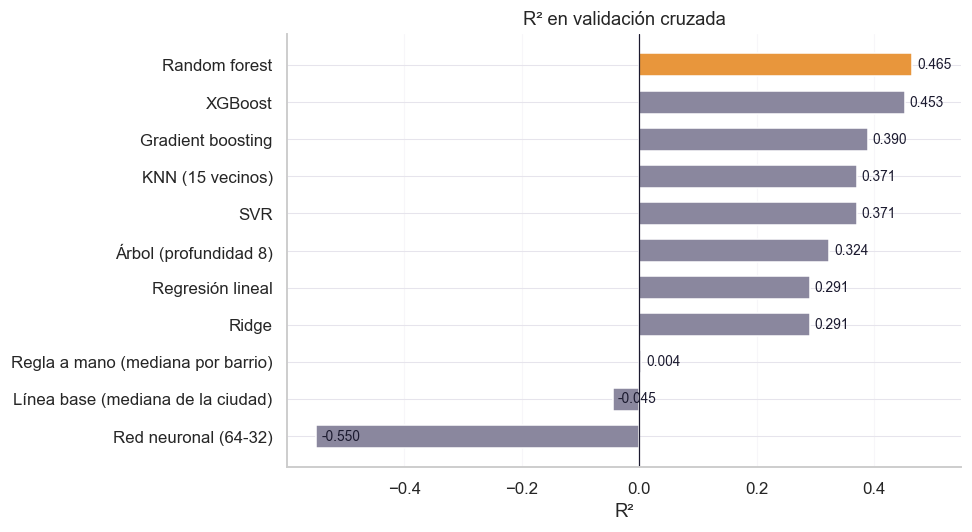

In [119]:
TINTA, ACENTO, GRIS = "#1B1A2F", "#E8963C", "#8A879E"

orden = resultados_sin.sort_values("R2")
mejor = resultados_sin["R2"].idxmax()
colores = [ACENTO if nombre == mejor else GRIS for nombre in orden.index]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(orden.index, orden["R2"], color=colores, height=0.62)
for i, valor in enumerate(orden["R2"]):
    ax.text(valor + 0.008, i, f"{valor:.3f}", va="center", fontsize=9, color=TINTA)
ax.axvline(0, color=TINTA, linewidth=0.8)
ax.set_xlim(min(0, orden["R2"].min()) - 0.05, orden["R2"].max() * 1.18)
ax.set_title("R² en validación cruzada")
ax.set_xlabel("R²")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Conclusión: modelos
Se compararon 9 modelos de 5 familias (lineales, vecinos, árboles, ensambles y SVR / red neuronal), más la línea base y la regla a mano, todos con la misma validación cruzada de 5 partes y con el preprocesamiento dentro del Pipeline. Los de árboles ganan a los lineales, porque el precio depende de combinaciones (tamaño con ubicación, por ejemplo). El mejor fue el Random forest (MAE **\$54.961**, R² 0,465), seguido de cerca por XGBoost (MAE **\$57.919**). La red neuronal tuvo un R² negativo (-0,550) porque unos pocos casos explotan al devolver el precio a pesos; no se afinó.

## Paso 6: Evaluación
Se elige entre los dos mejores, Random forest y XGBoost. Antes de decidir se mira si el Random forest gana en cada una de las 5 partes de la validación o solo en promedio. Después se evalúa el modelo elegido una sola vez con los datos de prueba, que no se habían tocado, y se compara con la regla a mano.

In [ ]:
por_parte = {}
for nombre in ["Random forest", "XGBoost"]:
    r = cross_validate(pipe(todos[nombre]), X_train, y_train, cv=cv, scoring=metricas_cv)
    por_parte[nombre] = -r["test_mae"]
    maes = por_parte[nombre]
    print(f"{nombre}: MAE por parte {[int(round(m)) for m in maes]} | promedio {maes.mean():,.0f} | desviación {maes.std():,.0f}")

gana_rf = (por_parte["Random forest"] < por_parte["XGBoost"]).sum()
print(f"El Random forest tiene menor MAE en {gana_rf} de 5 partes")

### Modelo elegido: Random forest
Entre Random forest y XGBoost, el Random forest tuvo menor error en las 4 métricas (MAE **\$54.961** contra **\$57.919**, RMSE **\$144.267** contra **\$145.924**, R² 0,465 contra 0,453 y RMSLE 0,358 contra 0,370) y ganó en las 5 partes de la validación, con una diferencia mayor que la variación entre partes (desviación de **\$1.730** y **\$1.878**). Además entrena en poco más de un segundo y no necesita afinar casi nada. Por eso se elige el Random forest.

In [ ]:
modelo_final = pipe(todos["Random forest"])
modelo_final.fit(X_train, y_train)
pred_rf = modelo_final.predict(X_test)

regla = ReglaPorBarrio().fit(X_train, y_train)
linea_base = DummyRegressor(strategy="median").fit(X_train, y_train)

final = pd.DataFrame({
    "Línea base": metricas(y_test, linea_base.predict(X_test)),
    "Regla a mano": metricas(y_test, regla.predict(X_test)),
    "Random forest (prueba)": metricas(y_test, pred_rf),
}).T
final.loc["Random forest (validación cruzada)"] = resultados_sin.loc["Random forest", ["MAE", "RMSE", "R2", "RMSLE"]]
display(final.map(lambda x: f"{x:,.3f}"))

mejora = (1 - final.loc["Random forest (prueba)", "MAE"] / final.loc["Regla a mano", "MAE"]) * 100
print(f"El Random forest reduce el MAE un {mejora:.1f}% frente a la regla a mano")


In [ ]:
# Precio predicho frente al observado, en la particion de prueba
fig, ejes = plt.subplots(1, 2, figsize=(11.5, 4.2))

limite = float(np.percentile(y_test, 99))
ejes[0].scatter(y_test, pred_rf, s=7, alpha=0.25, color=MORADO, edgecolors="none")
ejes[0].plot([0, limite], [0, limite], color=TINTA, linewidth=1, linestyle="--")
ejes[0].set_xlim(0, limite); ejes[0].set_ylim(0, limite)
ejes[0].set_title("Precio predicho y observado")
ejes[0].set_xlabel("precio observado"); ejes[0].set_ylabel("precio predicho")
ejes[0].text(limite * 0.05, limite * 0.92, "predicción perfecta", fontsize=8, color=TINTA)

residuo = pred_rf - y_test.to_numpy()
ejes[1].hist(residuo[np.abs(residuo) < limite], bins=60, color=ACENTO,
             edgecolor="white", linewidth=0.3)
ejes[1].axvline(0, color=TINTA, linewidth=1.2, linestyle="--")
ejes[1].set_title("Distribución del error")
ejes[1].set_xlabel("precio predicho menos precio observado"); ejes[1].set_ylabel("alojamientos")

plt.tight_layout()
plt.show()

In [ ]:
prep_final = modelo_final.regressor_.named_steps["prep"]
nombres = prep_final.named_steps["columnas"].get_feature_names_out()
importancias = pd.Series(modelo_final.regressor_.named_steps["modelo"].feature_importances_, index=nombres)

def variable_original(nombre):
    nombre = nombre.split("__", 1)[1]
    for c in CATEGORICAS:
        if nombre.startswith(c):
            return c
    return nombre

por_variable = importancias.groupby(variable_original).sum().sort_values(ascending=False)
display(por_variable.head(12).map(lambda x: f"{x * 100:,.1f}%"))

In [ ]:
# Peso de cada variable en el modelo elegido
top_importancia = por_variable.head(12).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hlines(top_importancia.index, 0, top_importancia.values * 100, color=GRIS, linewidth=1.2)
ax.plot(top_importancia.values * 100, top_importancia.index, "o", color=ACENTO, markersize=8)
ax.set_title("Peso de cada variable en el Random forest")
ax.set_xlabel("porcentaje de la importancia total")
plt.tight_layout()
plt.show()

In [ ]:
errores = pd.DataFrame({
    "real": y_test, "predicho": pred_rf, "room_type": X_test["room_type"]
})
errores["error_abs"] = (errores["real"] - errores["predicho"]).abs()
resumen_error = errores.groupby("room_type").agg(
    alojamientos=("real", "size"),
    precio_mediano=("real", "median"),
    MAE=("error_abs", "mean"),
)
resumen_error["error_relativo_%"] = resumen_error["MAE"] / resumen_error["precio_mediano"] * 100
display(resumen_error.sort_values("alojamientos", ascending=False).map(lambda x: f"{x:,.1f}"))

In [ ]:
# Error relativo segun el tipo de habitacion
orden_tipo = resumen_error.sort_values("alojamientos", ascending=True)

fig, ax = plt.subplots(figsize=(8, 3.4))
barras = ax.barh(orden_tipo.index, orden_tipo["error_relativo_%"], color=ACENTO, height=0.58)
for barra, (etiqueta, fila) in zip(barras, orden_tipo.iterrows()):
    ax.text(fila["error_relativo_%"] + 0.8, barra.get_y() + barra.get_height() / 2,
            f"{fila['error_relativo_%']:.0f} %  ({int(fila['alojamientos'])} alojamientos)",
            va="center", fontsize=8.5, color=TINTA)
ax.set_xlim(0, orden_tipo["error_relativo_%"].max() * 1.45)
ax.set_title("Error del modelo como porcentaje del precio típico")
ax.set_xlabel("error absoluto medio sobre el precio mediano del grupo")
plt.tight_layout()
plt.show()

In [ ]:
muestra = X_test.sample(5, random_state=42)
ejemplos = pd.DataFrame({
    "tipo de habitación": muestra["room_type"],
    "huéspedes": muestra["accommodates"],
    "barrio": muestra["neighbourhood_cleansed"],
    "precio real": y_test.loc[muestra.index],
    "precio predicho": modelo_final.predict(muestra),
})
ejemplos["error"] = ejemplos["precio predicho"] - ejemplos["precio real"]
display(ejemplos.round(0).map(lambda x: f"{x:,.0f}" if isinstance(x, (int, float)) else x))

### Conclusión: pregunta 1, ¿cuánto cobrar por noche?
El Random forest, entrenado con el logaritmo del precio, predice el precio por noche con un MAE de **\$55.218** en los datos de prueba, que no se habían tocado. Eso es un 40,6 % menos error que la regla a mano de la mediana por barrio (**\$92.943**), y su R² es 0,50 (la regla tiene 0,005). El resultado en la prueba es casi igual al de la validación cruzada (**\$54.961**), así que no se sobreajustó. Lo que más pesa es el tipo de habitación, el número de baños (columna creada desde el texto), la ubicación y las noches mínimas. Como no usa calificaciones ni comentarios, le sirve también a un dueño nuevo. El límite es que el error sigue siendo de entre un tercio y dos quintos del precio típico: el precio depende de cosas que no están en los datos (fotos, decoración, estado del inmueble).